# Three targets, 194 realities - WHO Triple Billion Project (2018–2025)
## Scarlette Berenice Alcaraz Muñiz - Maestría en ciencias de la computación - October 2026

## 1. Setup

In [61]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option("display.float_format", lambda x: f"{x:,.0f}")
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True)

COLORS = {"uhc": "#2a6fdb", "hep": "#e0633a", "hpop": "#2e9e6b"}
NAMES = {
    "uhc":  "Universal health coverage (UHC)",
    "hep":  "Health emergencies protection (HEP)",
    "hpop": "Healthier populations (HPOP)",
}
TARGET = 1_000_000_000
ORDER = ["uhc", "hep", "hpop"]

def millions(x, pos=None):
    return f"{x/1e6:,.0f} M"

def save(name):
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")

## 2. Load the data

In [62]:
df = pd.read_csv("dataset.csv", encoding="utf-8-sig")
print("Shape:", df.shape)
df.head(10)

Shape: (62712, 8)


,Area,Name,Year,Billion,Tracer,Mean_value,Lower_value,Upper_value
0,country,Afghanistan,2018,hep,detect_respond_contribution,0,0,0
1,country,Afghanistan,2018,hep,hep_espar_contribution,0,0,0
2,country,Afghanistan,2018,hep,hep_overall_contribution,0,0,0
3,country,Afghanistan,2018,hep,prevent_contribution,0,0,0
4,country,Afghanistan,2018,hpop,adult_obese_contribution,0,0,0
5,country,Afghanistan,2018,hpop,alcohol_contribution,0,0,0
6,country,Afghanistan,2018,hpop,child_obese_contribution,0,0,0
7,country,Afghanistan,2018,hpop,child_viol_contribution,0,0,0
8,country,Afghanistan,2018,hpop,devontrack_contribution,0,0,0
9,country,Afghanistan,2018,hpop,fuel_contribution,0,0,0


In [63]:
df.dtypes

Area            object
Name            object
Year             int64
Billion         object
Tracer          object
Mean_value     float64
Lower_value    float64
Upper_value    float64
dtype: object

## 3. Variables

In [64]:
print("Area   ->", df["Area"].unique())
print("Billion->", df["Billion"].unique())
print("Years  ->", sorted(df["Year"].unique()))
print("Distinct places:", df["Name"].nunique())
print("Indicators (Tracer):", df["Tracer"].nunique())
print()
print(df.groupby("Area")["Name"].nunique().rename("distinct places"))

Area   -> ['country' 'global' 'whoregion']
Billion-> ['hep' 'hpop' 'uhc']
Years  -> [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Distinct places: 201
Indicators (Tracer): 39

Area
country      194
global         1
whoregion      6
Name: distinct places, dtype: int64


In [65]:
df.groupby("Billion")["Tracer"].unique().apply(sorted)

Billion
hep     [detect_respond_contribution, hep_espar_contri...
hpop    [adult_obese_contribution, alcohol_contributio...
uhc     [anc4_contribution, art_contribution, beds_con...
Name: Tracer, dtype: object

In [66]:
indicator_names = {
    # HEP
    "detect_respond": "Detect and respond to emergencies",
    "hep_espar": "IHR capacities (e-SPAR)",
    "prevent": "Prevention (high-threat pathogen vaccination)",
    "hep_overall": "HEP TOTAL",
    # HPOP
    "adult_obese": "Adult obesity", "alcohol": "Alcohol consumption",
    "child_obese": "Child obesity", "child_viol": "Violence against children",
    "devontrack": "Early childhood development on track", "fuel": "Clean household fuels",
    "hpop_sanitation": "Safely managed sanitation", "hpop_tobacco": "Tobacco use",
    "ipv": "Intimate partner violence", "overweight": "Child overweight",
    "pm25": "Air pollution (PM2.5)", "road": "Road traffic deaths",
    "stunting": "Child stunting", "suicide": "Suicide mortality",
    "transfats": "Trans-fat policies", "wasting": "Child wasting",
    "water": "Safely managed drinking water", "hpop_overall": "HPOP TOTAL",
    # UHC
    "anc4": "Antenatal care (4+ visits)", "art": "Antiretroviral therapy (HIV)",
    "beds": "Hospital beds", "bp": "Hypertension control",
    "dtp3": "DTP3 immunization", "fh": "Financial protection (catastrophic spending)",
    "fp": "Family planning", "fpg": "Blood glucose / diabetes control",
    "hwf": "Health workforce", "itn": "Insecticide-treated nets (malaria)",
    "pneumo": "Pneumonia care", "population": "Population growth effect",
    "tb": "Tuberculosis treatment", "uhc_espar": "IHR capacities (UHC component)",
    "uhc_sanitation": "Sanitation (UHC component)", "uhc_tobacco": "Tobacco (UHC component)",
    "uhc_overall": "UHC TOTAL",
}
df["Indicator"] = df["Tracer"].str.replace("_contribution", "", regex=False)
df["Description"] = df["Indicator"].map(indicator_names)
df[["Billion", "Indicator", "Description"]].drop_duplicates().sort_values(["Billion", "Indicator"]).reset_index(drop=True)

,Billion,Indicator,Description
0,hep,detect_respond,Detect and respond to emergencies
1,hep,hep_espar,IHR capacities (e-SPAR)
2,hep,hep_overall,HEP TOTAL
3,hep,prevent,Prevention (high-threat pathogen vaccination)
4,hpop,adult_obese,Adult obesity
5,hpop,alcohol,Alcohol consumption
6,hpop,child_obese,Child obesity
7,hpop,child_viol,Violence against children
8,hpop,devontrack,Early childhood development on track
9,hpop,fuel,Clean household fuels


In [67]:
df["Interval_width"] = df["Upper_value"] - df["Lower_value"]
glob25 = df[(df["Area"] == "global") & (df["Year"] == 2025) & df["Indicator"].str.endswith("overall")]
glob25[["Billion", "Mean_value", "Lower_value", "Upper_value", "Interval_width"]]

,Billion,Mean_value,Lower_value,Upper_value,Interval_width
60803,hep,"697,610,249","592,967,427","796,137,091","203,169,663"
60811,hpop,"1,749,652,892","1,488,507,770","1,955,239,213","466,731,443"
60837,uhc,"567,152,651","532,955,591","599,392,783","66,437,192"


## 4. Data quality

In [68]:
print("Missing values per column:")
print(df.isna().sum()[["Area", "Name", "Year", "Billion", "Tracer", "Mean_value", "Lower_value", "Upper_value"]])
print("\nDuplicated rows:", df.duplicated().sum())
print("\nRows per place (8 years x 39 indicators = 312):")
print(df.groupby("Name").size().value_counts())

Missing values per column:
Area           0
Name           0
Year           0
Billion        0
Tracer         0
Mean_value     0
Lower_value    0
Upper_value    0
dtype: int64

Duplicated rows: 0

Rows per place (8 years x 39 indicators = 312):
312    201
Name: count, dtype: int64


## 5. Global progress vs. the 1-billion target

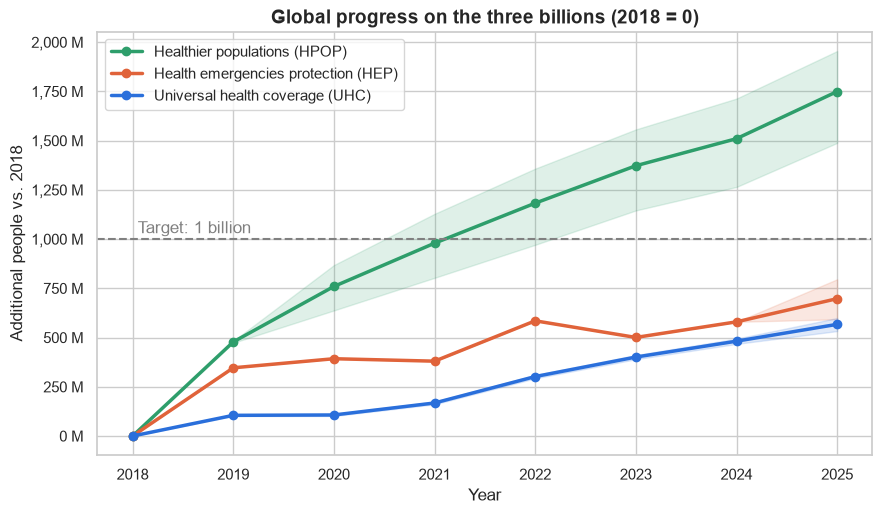

In [69]:
glob = df[(df["Area"] == "global") & df["Indicator"].str.endswith("overall")]

fig, ax = plt.subplots(figsize=(10, 5.5))
for b in ["hpop", "hep", "uhc"]:
    d = glob[glob["Billion"] == b].sort_values("Year")
    ax.plot(d["Year"], d["Mean_value"], marker="o", lw=2.5, color=COLORS[b], label=NAMES[b])
    ax.fill_between(d["Year"], d["Lower_value"], d["Upper_value"], color=COLORS[b], alpha=0.15)
ax.axhline(TARGET, ls="--", color="gray", lw=1.5)
ax.text(2018.05, TARGET * 1.03, "Target: 1 billion", color="gray")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set_title("Global progress on the three billions (2018 = 0)", fontsize=14, weight="bold")
ax.set_xlabel("Year"); ax.set_ylabel("Additional people vs. 2018")
ax.legend(loc="upper left")
save("01_global_vs_target")
plt.show()

In [70]:
progress = glob[glob["Year"] == 2025].set_index("Billion")[["Mean_value", "Lower_value", "Upper_value"]]
progress["% of target"] = (progress["Mean_value"] / TARGET * 100).round(1)
progress.rename(index=NAMES)

,Mean_value,Lower_value,Upper_value,% of target
Billion,,,,
Health emergencies protection (HEP),"697,610,249","592,967,427","796,137,091",70
Healthier populations (HPOP),"1,749,652,892","1,488,507,770","1,955,239,213",175
Universal health coverage (UHC),"567,152,651","532,955,591","599,392,783",57


## 6. Year-over-year change

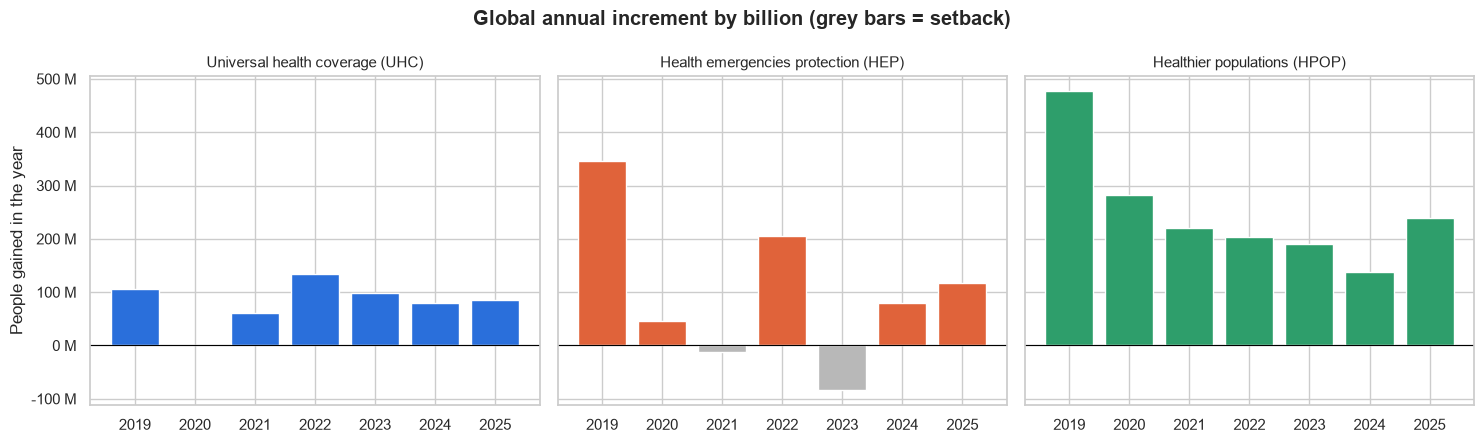

Billion,hep,hpop,uhc
Year,,,
2019,"346,436,267","477,950,554","105,071,250"
2020,"46,173,098","281,685,528","1,788,821"
2021,"-12,481,328","219,621,142","60,969,859"
2022,"204,954,398","203,389,432","134,161,643"
2023,"-84,442,870","190,001,947","99,090,693"
2024,"79,237,640","137,529,108","80,577,289"
2025,"117,733,044","239,475,180","85,493,095"


In [71]:
incr = (glob.sort_values("Year")
            .assign(Increment=lambda d: d.groupby("Billion")["Mean_value"].diff())
            .dropna(subset=["Increment"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, b in zip(axes, ORDER):
    d = incr[incr["Billion"] == b]
    bar_colors = [COLORS[b] if v >= 0 else "#b8b8b8" for v in d["Increment"]]
    ax.bar(d["Year"], d["Increment"], color=bar_colors)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(NAMES[b], fontsize=11)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
    ax.set_xticks(d["Year"])
axes[0].set_ylabel("People gained in the year")
fig.suptitle("Global annual increment by billion (grey bars = setback)", weight="bold")
plt.tight_layout()
save("02_annual_increment")
plt.show()

incr.pivot(index="Year", columns="Billion", values="Increment")

### 6.1 Lag plots — global cumulative values, lags 1, 2 and 3

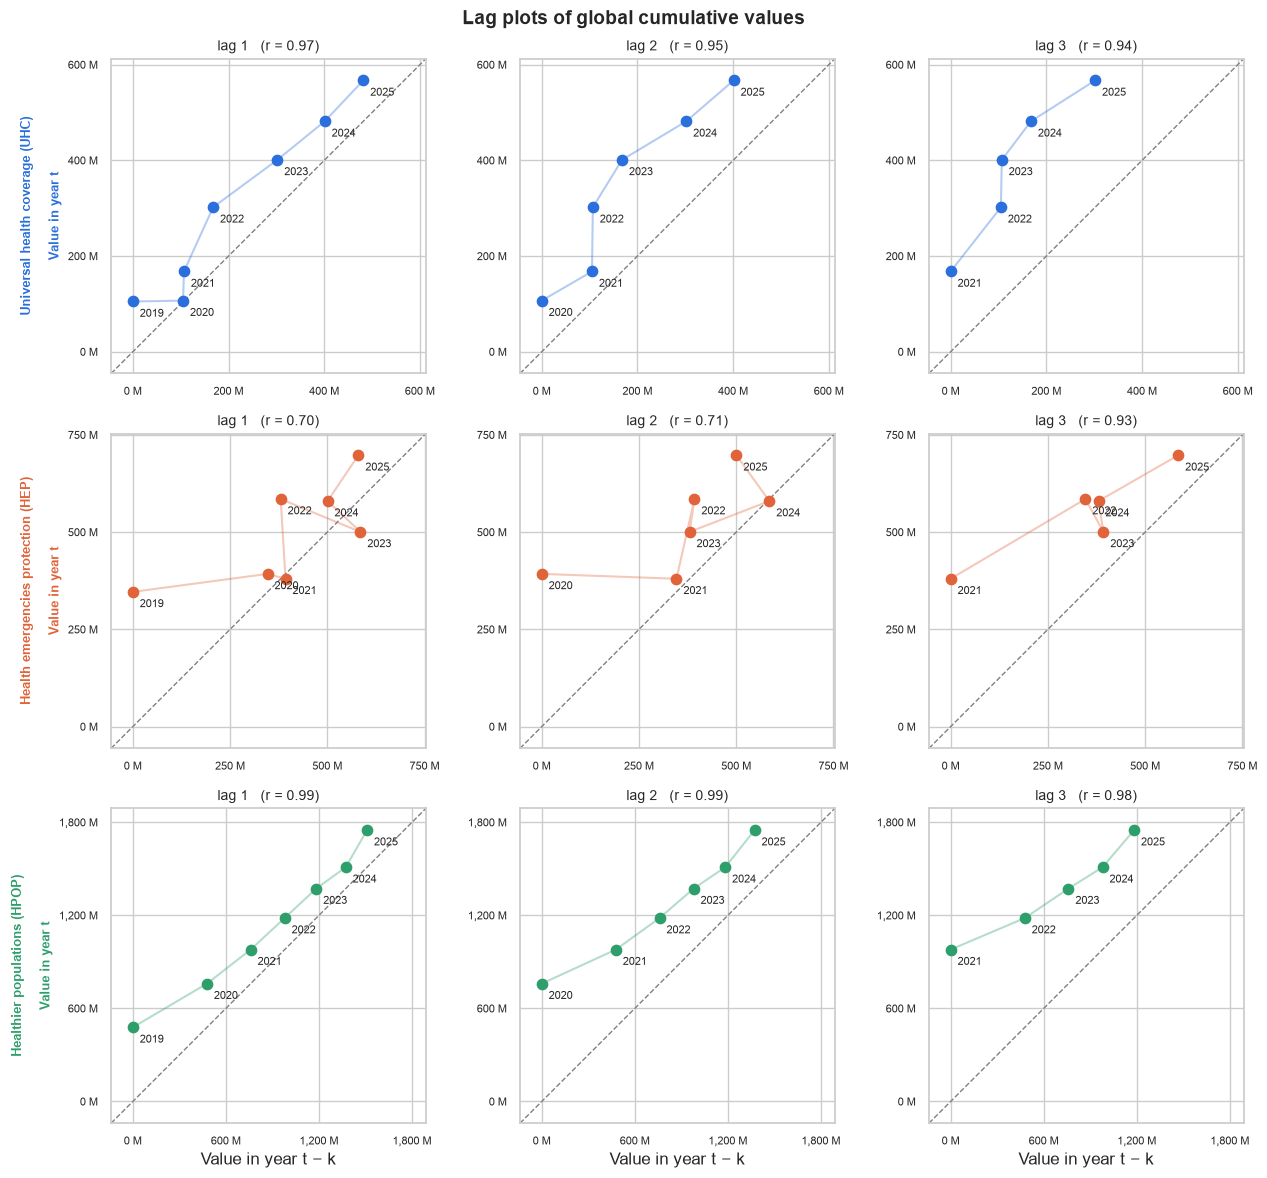

,lag 1,lag 2,lag 3
Universal health coverage (UHC),0.97,0.95,0.94
Health emergencies protection (HEP),0.70,0.71,0.93
Healthier populations (HPOP),0.99,0.99,0.98


In [72]:
global_series = {b: glob[glob["Billion"] == b].set_index("Year")["Mean_value"].sort_index() for b in ORDER}

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for row, b in enumerate(ORDER):
    s = global_series[b]
    lims = (s.min() - 0.08 * s.max(), s.max() * 1.08)
    for col, lag in enumerate([1, 2, 3]):
        ax = axes[row, col]
        x, y = s.shift(lag), s
        ok = x.notna()
        ax.plot(lims, lims, ls="--", color="gray", lw=1, zorder=1)
        ax.plot(x[ok], y[ok], color=COLORS[b], alpha=0.35, zorder=2)
        ax.scatter(x[ok], y[ok], s=55, color=COLORS[b], zorder=3)
        for year in s.index[ok]:
            ax.annotate(str(year), (x[year], y[year]), textcoords="offset points",
                        xytext=(5, -11), fontsize=8)
        ax.set(xlim=lims, ylim=lims, aspect="equal")
        ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
        ax.yaxis.set_major_locator(mticker.MaxNLocator(4))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(millions))
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
        ax.tick_params(labelsize=8)
        ax.set_title(f"lag {lag}   (r = {s.autocorr(lag=lag):.2f})", fontsize=10)
        if col == 0:
            ax.set_ylabel(f"{NAMES[b]}\n\nValue in year t", fontsize=9, color=COLORS[b], weight="bold")
        if row == 2:
            ax.set_xlabel("Value in year t − k")
fig.suptitle("Lag plots of global cumulative values", fontsize=14, weight="bold")
plt.tight_layout()
save("03_lag_plots")
plt.show()

autocorr = pd.DataFrame({f"lag {k}": [global_series[b].autocorr(lag=k) for b in ORDER] for k in [1, 2, 3]},
                        index=[NAMES[b] for b in ORDER])
with pd.option_context("display.float_format", "{:.2f}".format):
    display(autocorr)

## 7. WHO regions

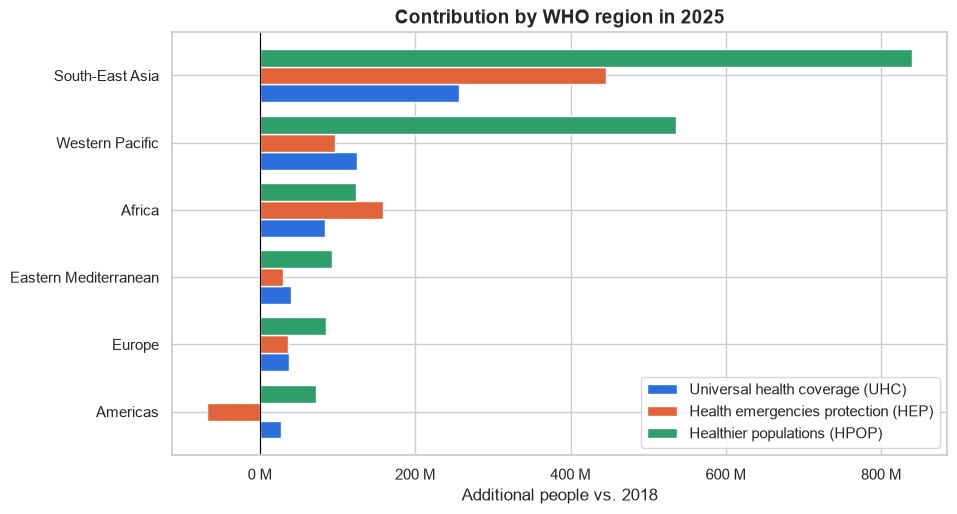

Billion,uhc,hep,hpop
Name,,,
Americas,"26,666,959","-67,934,512","72,497,728"
Europe,"36,807,827","35,948,794","85,263,566"
Eastern Mediterranean,"40,094,431","29,989,770","92,966,842"
Africa,"83,604,158","158,334,414","123,748,469"
Western Pacific,"124,495,493","95,912,656","535,886,335"
South-East Asia,"255,483,784","445,359,128","839,289,951"


In [73]:
reg = df[(df["Area"] == "whoregion") & df["Indicator"].str.endswith("overall")]
reg25 = reg[reg["Year"] == 2025].pivot(index="Name", columns="Billion", values="Mean_value")
reg25 = reg25[ORDER].sort_values("hpop")

ax = reg25.rename(columns=NAMES).plot(kind="barh", figsize=(10, 5.5),
                                      color=[COLORS[c] for c in reg25.columns], width=0.8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Contribution by WHO region in 2025", fontsize=14, weight="bold")
ax.set_xlabel("Additional people vs. 2018"); ax.set_ylabel("")
ax.legend(loc="lower right")
save("04_regions_2025")
plt.show()
reg25

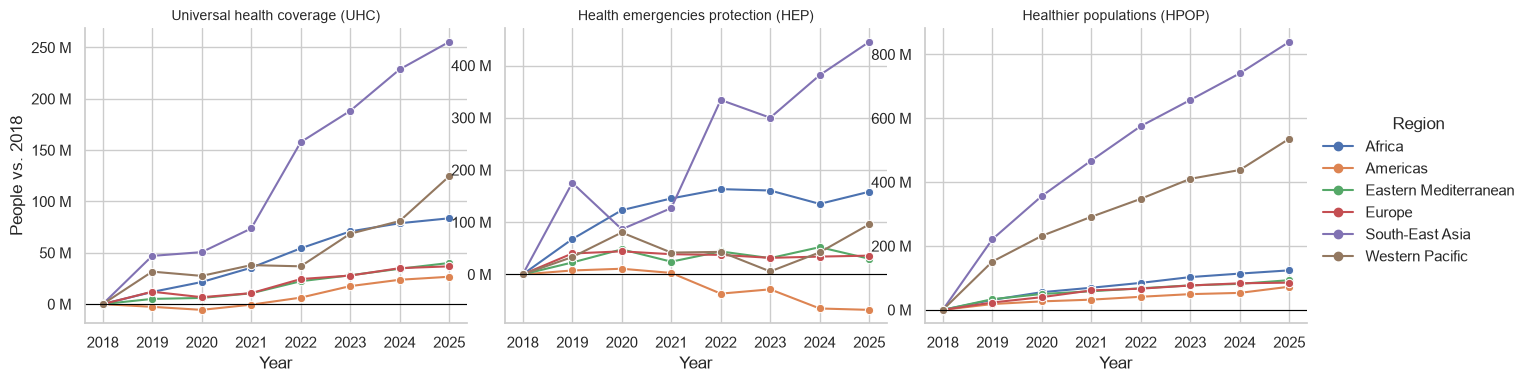

In [74]:
g = sns.relplot(data=reg, x="Year", y="Mean_value", hue="Name", col="Billion",
                col_order=ORDER, kind="line", marker="o",
                height=4, aspect=1.1, facet_kws={"sharey": False})
for ax, b in zip(g.axes.flat, ORDER):
    ax.set_title(NAMES[b], fontsize=10)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
    ax.axhline(0, color="black", lw=0.8)
g.set_axis_labels("Year", "People vs. 2018")
g._legend.set_title("Region")
save("05_regions_trend")
plt.show()

## 8. Countries: distribution and outliers

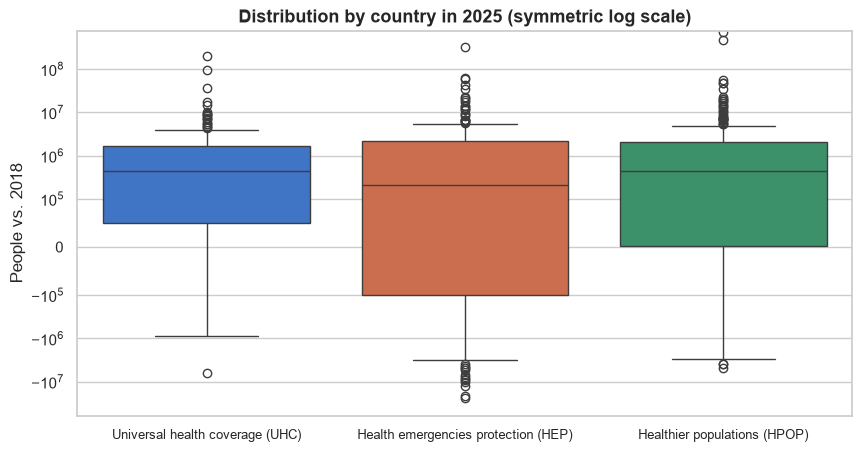

,count,mean,std,min,25%,50%,75%,max
Billion,,,,,,,,
hep,194,"3,595,929","24,293,391","-24,148,905","-101,527","206,832","2,179,157","317,982,702"
hpop,194,"9,018,829","62,275,112","-4,785,409",948,"438,142","2,070,012","723,934,924"
uhc,194,"2,923,467","15,675,507","-6,152,652","49,235","445,865","1,661,709","194,203,249"


In [75]:
countries25 = df[(df["Area"] == "country") & (df["Year"] == 2025) & df["Indicator"].str.endswith("overall")].copy()

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=countries25, x="Billion", y="Mean_value", order=ORDER,
            hue="Billion", palette=COLORS, legend=False, ax=ax)
ax.set_yscale("symlog", linthresh=1e5)
ax.set_xticks(range(3)); ax.set_xticklabels([NAMES[b] for b in ORDER], fontsize=9)
ax.set_title("Distribution by country in 2025 (symmetric log scale)", fontsize=13, weight="bold")
ax.set_xlabel(""); ax.set_ylabel("People vs. 2018")
save("06_country_boxplot")
plt.show()

countries25.groupby("Billion")["Mean_value"].describe()

In [76]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

countries25["Outlier"] = countries25.groupby("Billion")["Mean_value"].transform(iqr_outliers)
print("Outlier countries per billion:")
print(countries25.groupby("Billion")["Outlier"].sum())

for b in ORDER:
    d = countries25[countries25["Billion"] == b].sort_values("Mean_value")
    print(f"\n=== {NAMES[b]} ===")
    print("Top 5:   ", ", ".join(f"{n} ({v/1e6:,.1f} M)" for n, v in zip(d["Name"].tail(5)[::-1], d["Mean_value"].tail(5)[::-1])))
    print("Bottom 5:", ", ".join(f"{n} ({v/1e6:,.1f} M)" for n, v in zip(d["Name"].head(5), d["Mean_value"].head(5))))

Outlier countries per billion:
Billion
hep     36
hpop    34
uhc     20
Name: Outlier, dtype: int64

=== Universal health coverage (UHC) ===
Top 5:    India (194.2 M), China (92.8 M), Indonesia (35.5 M), Nigeria (17.2 M), Pakistan (14.9 M)
Bottom 5: Brazil (-6.2 M), Ukraine (-0.9 M), Bulgaria (-0.1 M), Tunisia (-0.1 M), Belarus (-0.1 M)

=== Health emergencies protection (HEP) ===
Top 5:    India (318.0 M), China (61.2 M), Indonesia (59.4 M), Bangladesh (42.1 M), Pakistan (34.2 M)
Bottom 5: Mexico (-24.1 M), United States of America (-21.7 M), Brazil (-12.5 M), Iraq (-10.3 M), Syrian Arab Republic (-9.1 M)

=== Healthier populations (HPOP) ===
Top 5:    India (723.9 M), China (476.6 M), Pakistan (57.1 M), Nigeria (47.2 M), Bangladesh (46.9 M)
Bottom 5: Iran (Islamic Republic of) (-4.8 M), Algeria (-3.9 M), Yemen (-3.8 M), Syrian Arab Republic (-3.0 M), Malaysia (-1.5 M)


## 9. Contribution by indicator (global, 2025)

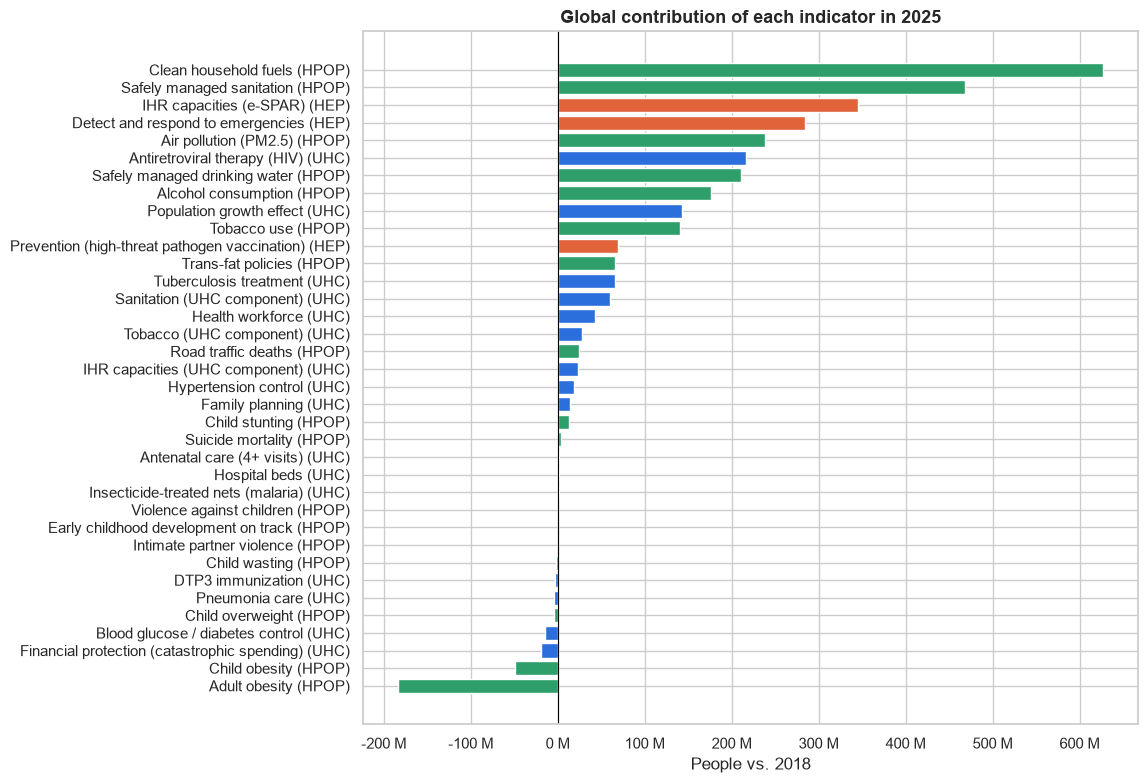

In [77]:
comp = df[(df["Area"] == "global") & (df["Year"] == 2025) & ~df["Indicator"].str.endswith("overall")].copy()
comp = comp[comp["Mean_value"] != 0].sort_values("Mean_value")
comp["Label"] = comp["Description"] + " (" + comp["Billion"].str.upper() + ")"

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(comp["Label"], comp["Mean_value"], color=comp["Billion"].map(COLORS))
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set_title("Global contribution of each indicator in 2025", fontsize=13, weight="bold")
ax.set_xlabel("People vs. 2018")
save("07_indicators_global")
plt.show()

## 10. Mexico

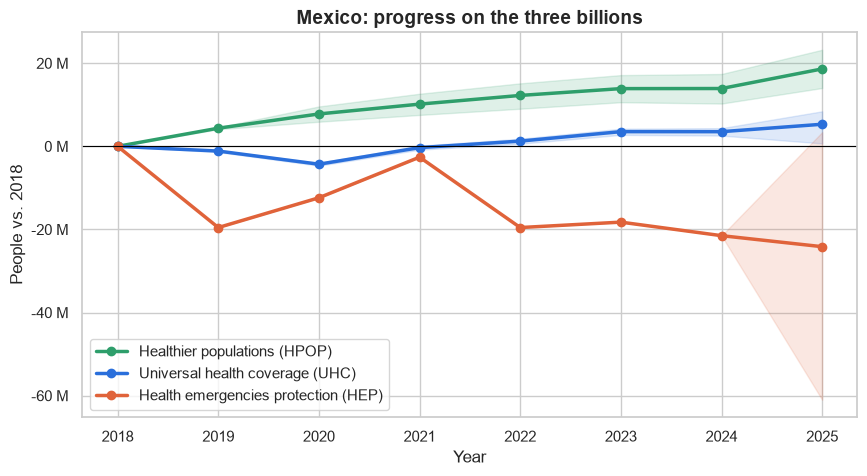

Billion,hep,hpop,uhc
Year,,,
2018,0,0,0
2019,"-19,545,209","4,362,376","-1,138,660"
2020,"-12,378,632","7,793,217","-4,303,265"
2021,"-2,606,028","10,158,910","-310,074"
2022,"-19,545,209","12,249,910","1,256,548"
2023,"-18,242,195","13,890,291","3,535,102"
2024,"-21,499,730","13,912,759","3,525,423"
2025,"-24,148,905","18,635,155","5,314,354"


In [78]:
mx = df[(df["Name"] == "Mexico") & df["Indicator"].str.endswith("overall")]

fig, ax = plt.subplots(figsize=(10, 5))
for b in ["hpop", "uhc", "hep"]:
    d = mx[mx["Billion"] == b].sort_values("Year")
    ax.plot(d["Year"], d["Mean_value"], marker="o", lw=2.5, color=COLORS[b], label=NAMES[b])
    ax.fill_between(d["Year"], d["Lower_value"], d["Upper_value"], color=COLORS[b], alpha=0.15)
ax.axhline(0, color="black", lw=0.8)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set_title("Mexico: progress on the three billions", fontsize=14, weight="bold")
ax.set_xlabel("Year"); ax.set_ylabel("People vs. 2018")
ax.legend(loc="lower left")
save("08_mexico_trend")
plt.show()

mx.pivot(index="Year", columns="Billion", values="Mean_value")

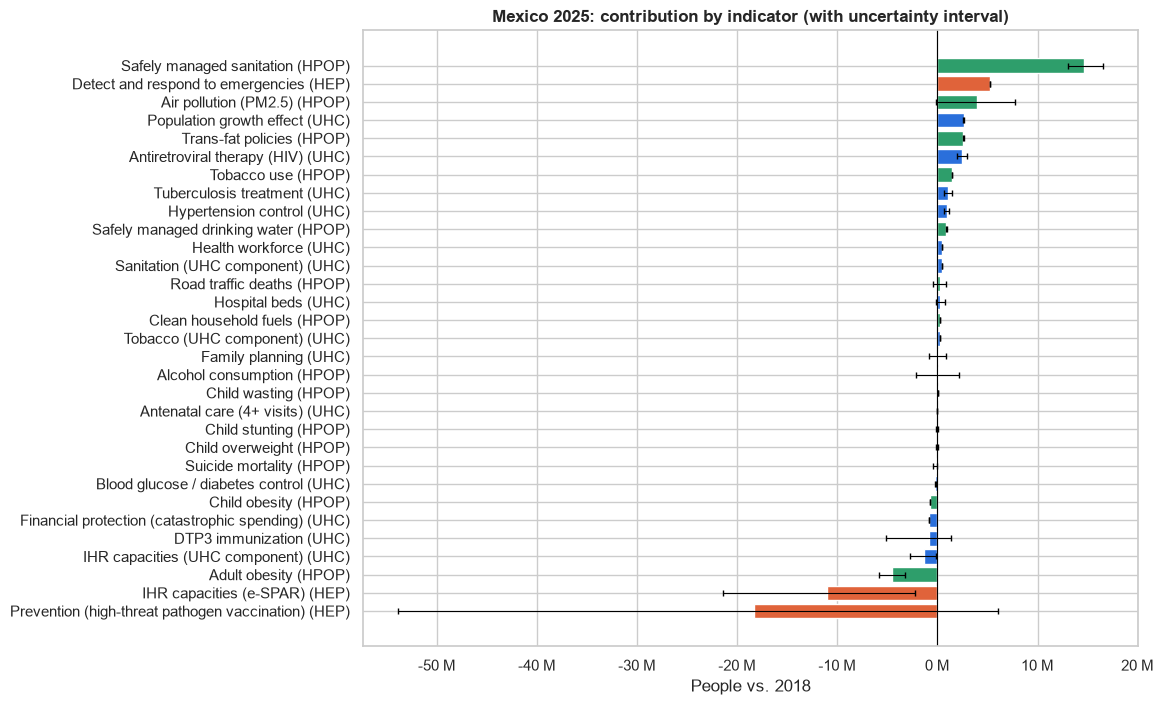

In [79]:
mx25 = df[(df["Name"] == "Mexico") & (df["Year"] == 2025) & ~df["Indicator"].str.endswith("overall")].copy()
mx25 = mx25[mx25["Mean_value"] != 0].sort_values("Mean_value")
mx25["Label"] = mx25["Description"] + " (" + mx25["Billion"].str.upper() + ")"

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(mx25["Label"], mx25["Mean_value"], color=mx25["Billion"].map(COLORS))
ax.errorbar(mx25["Mean_value"], mx25["Label"],
            xerr=[mx25["Mean_value"] - mx25["Lower_value"], mx25["Upper_value"] - mx25["Mean_value"]],
            fmt="none", ecolor="black", elinewidth=0.8, capsize=2)
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set_title("Mexico 2025: contribution by indicator (with uncertainty interval)", fontsize=12, weight="bold")
ax.set_xlabel("People vs. 2018")
save("09_mexico_indicators")
plt.show()

## 11. Summary of findings

In [80]:
print("=== GLOBAL 2025 ===")
for b in ["hpop", "hep", "uhc"]:
    r = glob[(glob["Year"] == 2025) & (glob["Billion"] == b)].iloc[0]
    print(f"{NAMES[b]:40s} {r.Mean_value/1e6:>8,.0f} M  ({r.Mean_value/TARGET:.0%} of target)  "
          f"UI: [{r.Lower_value/1e6:,.0f} M, {r.Upper_value/1e6:,.0f} M]")

print("\n=== GLOBAL SETBACK YEARS ===")
neg = incr[incr["Increment"] < 0]
print(neg[["Billion", "Year", "Increment"]].to_string(index=False) if len(neg) else "None")

print("\n=== MEXICO 2025 ===")
for b in ["hpop", "hep", "uhc"]:
    r = mx[(mx["Year"] == 2025) & (mx["Billion"] == b)].iloc[0]
    print(f"{NAMES[b]:40s} {r.Mean_value/1e6:>8,.1f} M  UI: [{r.Lower_value/1e6:,.1f} M, {r.Upper_value/1e6:,.1f} M]")

=== GLOBAL 2025 ===
Healthier populations (HPOP)                1,750 M  (175% of target)  UI: [1,489 M, 1,955 M]
Health emergencies protection (HEP)           698 M  (70% of target)  UI: [593 M, 796 M]
Universal health coverage (UHC)               567 M  (57% of target)  UI: [533 M, 599 M]

=== GLOBAL SETBACK YEARS ===
Billion  Year   Increment
    hep  2021 -12,481,328
    hep  2023 -84,442,870

=== MEXICO 2025 ===
Healthier populations (HPOP)                 18.6 M  UI: [14.0 M, 23.2 M]
Health emergencies protection (HEP)         -24.1 M  UI: [-61.0 M, 3.4 M]
Universal health coverage (UHC)               5.3 M  UI: [0.7 M, 8.4 M]
